# V2 第三部分　開窗高度，兩條路徑各自接在最佳止點

⭐ 結果頁在 Obsidian `15 Simulation subjects/V2/V2 P3 開窗高度 — 結果.md`。 / 第一部分找最佳止點，第二部分比路徑，這一本補開窗高度。

## 0. 📖 故事：為什麼要做這一本

1. 第一版的開窗高度掃描（H1）兩條路徑都接中間楔狀骨（intermediate cuneiform），V2 的止點已經換了
    - IO 接位置 2.75，中間楔往外側楔四分之三
    - CT 接位置 1.00，內側楔狀骨（medial cuneiform）
2. BOA 投影片要用同一組止點，所以用 V2 的止點重跑一次
3. 要回答三件事
    - 高度會不會改變背屈（dorsiflexion）力矩和後足方向
    - 窗口那一彎和支持帶（retinaculum）那一彎在幾公分平衡
    - 和第一版比，平衡高度有沒有移
4. 每個報告的高度都存一個 .osim，GUI 可以直接打開截圖
5. 圖上文字全部英文，不寫人名，IO 藍 #1f77b4、CT 橘 #ff7f0e，角度用 V2 選止點的 14°

## 1. 設定

### 📖 1.1. 載入引擎，從第一部分的 CSV 讀出最佳止點

1. 最佳止點不手打，直接從 `V2_part1_attachment_sweep.csv` 用同一個規則挑，位置 1 到 5 裡 14° 背屈力臂最大的點
2. 高度從內踝尖以上 4 cm 到 12 cm，每 0.25 cm 一點，和第一版一樣
3. 支持帶那一點（P3）照第一版的規則跟著開窗中段點走

In [ ]:
import csv  # 讀寫 CSV
import os  # 組路徑
import re  # 改 .osim 裡的文字
import sys  # 讓 python 找得到 V2 的引擎

import matplotlib.pyplot as plt  # 畫圖
import numpy as np  # 陣列
import opensim as osim  # OpenSim API
from tqdm import tqdm  # 進度條

ROOT = r"D:\OpenSim 4.6\Tendon transfer model\V2"  # V2 的程式資料夾
MODEL = os.path.join(ROOT, 'model', 'gait2392_simbody_original.osim')  # 原始 Gait2392
FIGURES = os.path.join(ROOT, 'figures')  # 圖存這裡，之後複製到 Obsidian
MODELS_DIR = os.path.join(ROOT, 'models', 'part3')  # 第三部分的 .osim 存這裡
sys.path.insert(0, ROOT)  # 先找 V2 自己的引擎
from transfer_engine import TransferEngine, via_y_from_height  # noqa: E402

ROUTES = {'IO': -0.020, 'CT': 0.028}  # 開窗中段點的內外側座標 z，公尺
COLOUR = {'IO': '#1f77b4', 'CT': '#ff7f0e'}  # 和模型、V2 其他圖同色
HEIGHTS = [round(4.0 + 0.25 * i, 2) for i in range(33)]  # 4 到 12 cm，每 0.25 cm
REPORT = [0, 14]  # 報數字的兩個角度，中立位和步態裡最大的背屈

with open(os.path.join(ROOT, 'V2_part1_attachment_sweep.csv'), encoding='utf-8') as handle:
    part1 = [{key: (value if key in ('route', 'insertion') else float(value))
              for key, value in row.items()} for row in csv.DictReader(handle)]


def best_row(route):
    """位置 1 到 5 裡面，14° 背屈力臂最大的那一列。"""
    mine = [row for row in part1 if row['route'] == route and row['position'] >= 1]
    return max(mine, key=lambda row: row['dorsi_arm_14deg_mm'])


BEST = {}  # 路徑 → (位置, 止點座標公尺, 名稱)
for route in ROUTES:
    row = best_row(route)
    BEST[route] = (row['position'], (row['x_mm'] / 1000, row['y_mm'] / 1000, row['z_mm'] / 1000),
                   row['insertion'])
    print(f"{route}: best insertion at position {row['position']:.2f} ({row['insertion']}), "
          f"{row['dorsi_arm_14deg_mm']:.2f} mm at 14 deg")

engine = TransferEngine(MODEL)  # 一個引擎從頭用到尾
print(f'{len(HEIGHTS)} heights from {HEIGHTS[0]} to {HEIGHTS[-1]} cm')

IO: best insertion at position 2.75 (intermediate_cuneiform_to_lateral_cuneiform), 32.37 mm at 14 deg
CT: best insertion at position 1.00 (medial_cuneiform), 24.65 mm at 14 deg
33 heights from 4.0 to 12.0 cm


### 👀 1.1. 用哪兩個止點

1. 和第一部分一樣，IO 接位置 2.75（14° 背屈力臂 32.37 mm），CT 接內側楔狀骨（24.65 mm）
2. 高度 4 到 12 cm 共 33 點

## 2. 掃高度

### 📖 2.1. 每條路徑、每個高度算一次

1. `evaluate` 一次給出力矩、兩個轉折角和淨後足力矩
2. 轉折角是兩段直線的夾角，180° 是完全直
    - **窗口那一彎**　起點 → 開窗點 → 支持帶那一點
    - **支持帶那一彎**　開窗點 → 支持帶那一點 → 止點
3. 每一列寫進 `V2_part3_height_at_best.csv`

In [ ]:
rows = []
for route, z in ROUTES.items():
    position, xyz, label = BEST[route]
    for height in tqdm(HEIGHTS, desc=f'{route} heights'):
        result = engine.evaluate(z, height, insertion=xyz)  # 支持帶點跟著中段點走
        angles = result['angles']
        row = {'route': route, 'position': position, 'insertion': label, 'height_cm': height,
               'bend_window_deg': result['bend']['window_deg'],
               'bend_retinaculum_deg': result['bend']['retinaculum_deg'],
               'tendon_slack_mm': result['tendon_slack_mm']}
        for angle in REPORT:
            i = angles.index(angle)
            row[f'dorsi_moment_{angle}deg_Nm'] = result['dorsi_moment'][i]
            row[f'supination_moment_{angle}deg_Nm'] = result['hindfoot_moment'][i]
            row[f'net_deep_{angle}deg_Nm'] = result['net_hindfoot']['deep'][i]
            row[f'net_common_{angle}deg_Nm'] = result['net_hindfoot']['common'][i]
        rows.append(row)

with open(os.path.join(ROOT, 'V2_part3_height_at_best.csv'), 'w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

table = {route: [row for row in rows if row['route'] == route] for route in ROUTES}
for route in ROUTES:
    print(route)
    for row in table[route]:
        if row['height_cm'] in (4.0, 7.5, 10.0, 12.0):
            print(f"  {row['height_cm']:5.2f} cm  window bend {row['bend_window_deg']:6.1f} deg  "
                  f"retinaculum bend {row['bend_retinaculum_deg']:6.1f} deg  "
                  f"DF {row['dorsi_moment_0deg_Nm']:5.2f} / {row['dorsi_moment_14deg_Nm']:5.2f} Nm  "
                  f"supination {row['supination_moment_0deg_Nm']:+6.2f} / {row['supination_moment_14deg_Nm']:+6.2f} Nm")

IO
   4.00 cm  window bend  144.1 deg  retinaculum bend  161.2 deg  DF 44.46 / 30.15 Nm  supination -11.52 /  -6.62 Nm
   7.50 cm  window bend  158.6 deg  retinaculum bend  167.8 deg  DF 44.62 / 30.31 Nm  supination -11.56 /  -6.65 Nm
  10.00 cm  window bend  163.1 deg  retinaculum bend  166.6 deg  DF 44.67 / 30.36 Nm  supination -11.57 /  -6.66 Nm
  12.00 cm  window bend  165.0 deg  retinaculum bend  165.3 deg  DF 44.69 / 30.38 Nm  supination -11.58 /  -6.67 Nm
CT
   4.00 cm  window bend  141.6 deg  retinaculum bend  148.0 deg  DF 37.36 / 23.88 Nm  supination  +9.40 /  +7.10 Nm
   7.50 cm  window bend  155.6 deg  retinaculum bend  146.1 deg  DF 37.50 / 24.00 Nm  supination  +9.43 /  +7.14 Nm
  10.00 cm  window bend  159.5 deg  retinaculum bend  144.2 deg  DF 37.53 / 24.03 Nm  supination  +9.44 /  +7.15 Nm
  12.00 cm  window bend  160.8 deg  retinaculum bend  143.0 deg  DF 37.55 / 24.04 Nm  supination  +9.44 /  +7.15 Nm


### 👀 2.1. 四個高度的數字

| 路徑 | 高度 | 窗口那一彎 | 支持帶那一彎 | 背屈力矩 0° / 14° | 旋後力矩 0° / 14° |
|---|---|---|---|---|---|
| IO | 4 cm | 144.1° | 161.2° | 44.46 / 30.15 Nm | −11.52 / −6.62 Nm |
| IO | 7.5 cm | 158.6° | 167.8° | 44.62 / 30.31 Nm | −11.56 / −6.65 Nm |
| IO | 10 cm | 163.1° | 166.6° | 44.67 / 30.36 Nm | −11.57 / −6.66 Nm |
| IO | 12 cm | 165.0° | 165.3° | 44.69 / 30.38 Nm | −11.58 / −6.67 Nm |
| CT | 4 cm | 141.6° | 148.0° | 37.36 / 23.88 Nm | +9.40 / +7.10 Nm |
| CT | 7.5 cm | 155.6° | 146.1° | 37.50 / 24.00 Nm | +9.43 / +7.14 Nm |
| CT | 10 cm | 159.5° | 144.2° | 37.53 / 24.03 Nm | +9.44 / +7.15 Nm |
| CT | 12 cm | 160.8° | 143.0° | 37.55 / 24.04 Nm | +9.44 / +7.15 Nm |

1. 窗口那一彎兩條都是越高越直
2. ⭐ 支持帶那一彎兩條不一樣，IO 一直都比窗口直，CT 越高越彎
3. 力矩幾乎是水平線

### 📖 2.2. 對帳：7.5 cm 那一點要和第二部分一模一樣

1. 第二部分的 A 組合就是開窗 7.5 cm，同樣的止點
2. 對得上，才能說這一本和前兩本是同一套計算
3. 順便用第一版的止點（中間楔狀骨）算平衡高度，要回到第一版 H1 的 IO 約 7 到 7.25、CT 約 7.5 cm

In [ ]:
PART2 = {  # 第二部分 notebook §5.1 的數字，Nm
    'IO': {'dorsi_0': 44.621, 'dorsi_14': 30.3103, 'sup_14': -6.6523},
    'CT': {'dorsi_0': 37.4969, 'dorsi_14': 24.0031, 'sup_14': 7.1374},
}
for route in ROUTES:
    row = next(r for r in table[route] if r['height_cm'] == 7.5)
    mine = (row['dorsi_moment_0deg_Nm'], row['dorsi_moment_14deg_Nm'], row['supination_moment_14deg_Nm'])
    theirs = (PART2[route]['dorsi_0'], PART2[route]['dorsi_14'], PART2[route]['sup_14'])
    gap = max(abs(a - b) for a, b in zip(mine, theirs))
    print(f'{route} at 7.5 cm: DF {mine[0]:.3f} / {mine[1]:.3f}, supination at 14 deg {mine[2]:+.3f} Nm, '
          f'largest gap from part 2 {gap:.4f} Nm')


def crossing(heights, first, second):
    """兩條曲線相交的高度，線性內插。"""
    difference = np.array(first) - np.array(second)
    for i in range(len(heights) - 1):
        if difference[i] == 0:
            return heights[i]
        if difference[i] * difference[i + 1] < 0:
            t = difference[i] / (difference[i] - difference[i + 1])
            return heights[i] + t * (heights[i + 1] - heights[i])
    return float('nan')


for route, z in ROUTES.items():  # 第一版的止點，確認平衡高度的算法沒變
    window, retinaculum = [], []
    for height in HEIGHTS:
        result = engine.evaluate(z, height, insertion='intermediate_cuneiform')
        window.append(result['bend']['window_deg'])
        retinaculum.append(result['bend']['retinaculum_deg'])
    print(f'{route} with the version 1 insertion (intermediate cuneiform): bends balance at '
          f'{crossing(HEIGHTS, window, retinaculum):.2f} cm')

IO at 7.5 cm: DF 44.621 / 30.310, supination at 14 deg -6.652 Nm, largest gap from part 2 0.0000 Nm
CT at 7.5 cm: DF 37.497 / 24.003, supination at 14 deg +7.137 Nm, largest gap from part 2 0.0000 Nm
IO with the version 1 insertion (intermediate cuneiform): bends balance at 7.18 cm
CT with the version 1 insertion (intermediate cuneiform): bends balance at 7.62 cm


### 👀 2.2. 對帳結果

1. ✅ 7.5 cm 那一點和第二部分差 0.0000 Nm，是同一套計算
2. ✅ 換回第一版的止點，平衡高度是 IO 7.18 cm、CT 7.62 cm，和第一版 H1 的「IO 約 7 到 7.25、CT 約 7.5 cm」一致
3. ⭐ 所以下面平衡高度的改變，完全來自止點換了，不是算法變了

## 3. 平衡高度和力矩變多少

### 📖 3.1. 兩個轉折在哪裡平衡，力矩隨高度變多少

1. 平衡高度 ＝ 窗口那一彎和支持帶那一彎一樣大的高度，兩條曲線的交點
    - ⚠️ 兩條線在 4 到 12 cm 之間不一定會交叉，不交叉就沒有平衡高度
2. 所以另外算**最直的高度**　每個高度取兩個彎裡比較彎的那一個，找它最大的高度
    - 整段 4 到 12 cm 找一次，只到 10 cm 再找一次，因為 10 cm 以上會切到肌肉
3. 力矩變化用「最大減最小，除以平均」，4 到 12 cm 整段

In [ ]:
BALANCE, STRAIGHTEST, LIMITING = {}, {}, {}
for route in ROUTES:
    heights = [row['height_cm'] for row in table[route]]
    window = [row['bend_window_deg'] for row in table[route]]
    retinaculum = [row['bend_retinaculum_deg'] for row in table[route]]
    BALANCE[route] = crossing(heights, window, retinaculum)
    if np.isfinite(BALANCE[route]):
        bend = np.interp(BALANCE[route], heights, window)
        print(f'{route}: the two bends balance at {BALANCE[route]:.2f} cm, both about {bend:.1f} deg')
    else:
        print(f'{route}: the two bends never cross between 4 and 12 cm')
    LIMITING[route] = np.minimum(window, retinaculum)  # 每個高度比較彎的那一個
    sharper = ['window' if w < r else 'retinaculum' for w, r in zip(window, retinaculum)]
    for top in (12.0, 10.0):
        allowed = [i for i, h in enumerate(heights) if h <= top]
        best = max(allowed, key=lambda i: LIMITING[route][i])
        STRAIGHTEST[(route, top)] = heights[best]
        print(f'   straightest up to {top:.0f} cm: {heights[best]:.2f} cm, the sharper bend there is '
              f'{LIMITING[route][best]:.1f} deg ({sharper[best]})')
    for height in (7.5, 10.0):
        i = heights.index(height)
        print(f'   at {height} cm the sharper bend is the {sharper[i]}, {LIMITING[route][i]:.1f} deg')

print('\nchange across 4 to 12 cm, (max - min) / mean')
for route in ROUTES:
    for field in ('dorsi_moment_0deg_Nm', 'dorsi_moment_14deg_Nm',
                  'supination_moment_0deg_Nm', 'supination_moment_14deg_Nm'):
        values = np.array([row[field] for row in table[route]])
        change = (values.max() - values.min()) / abs(values.mean()) * 100
        print(f'  {route} {field:28s} {values.min():+7.2f} to {values.max():+7.2f} Nm, {change:.2f} %')

io = {row['height_cm']: row['bend_window_deg'] for row in table['IO']}
ct = {row['height_cm']: row['bend_window_deg'] for row in table['CT']}
gaps = [io[h] - ct[h] for h in HEIGHTS]
print(f'\nCT window bend is sharper than IO by {min(gaps):.1f} to {max(gaps):.1f} deg at every height')

IO: the two bends never cross between 4 and 12 cm
   straightest up to 12 cm: 12.00 cm, the sharper bend there is 165.0 deg (window)
   straightest up to 10 cm: 10.00 cm, the sharper bend there is 163.1 deg (window)
   at 7.5 cm the sharper bend is the window, 158.6 deg
   at 10.0 cm the sharper bend is the window, 163.1 deg
CT: the two bends balance at 5.15 cm, both about 147.9 deg
   straightest up to 12 cm: 5.25 cm, the sharper bend there is 147.9 deg (retinaculum)
   straightest up to 10 cm: 5.25 cm, the sharper bend there is 147.9 deg (retinaculum)
   at 7.5 cm the sharper bend is the retinaculum, 146.1 deg
   at 10.0 cm the sharper bend is the retinaculum, 144.2 deg

change across 4 to 12 cm, (max - min) / mean
  IO dorsi_moment_0deg_Nm          +44.46 to  +44.69 Nm, 0.51 %
  IO dorsi_moment_14deg_Nm         +30.15 to  +30.38 Nm, 0.75 %
  IO supination_moment_0deg_Nm     -11.58 to  -11.52 Nm, 0.51 %
  IO supination_moment_14deg_Nm     -6.67 to   -6.62 Nm, 0.75 %
  CT dorsi_moment

### 👀 3.1. 平衡高度移了，而且兩條路徑不一樣

1. ⭐⭐ **IO 沒有平衡高度**　4 到 12 cm 之間，窗口那一彎一直比支持帶那一彎彎，所以**越高越直**
    - 7.5 cm 時最彎的是 158.6°，10 cm 時 163.1°
2. ⭐⭐ **CT 在 5.15 cm 平衡**，兩個彎都約 147.9°
    - 再往上，支持帶那一彎變成比較彎的那個，而且越來越彎，7.5 cm 146.1°、10 cm 144.2°
    - 所以 CT 開高一點，路徑反而不會比較直
3. ✅ 力矩隨高度的變化只有 0.50% 到 0.75%，高度不影響力量和方向
4. ✅ 同一個高度，CT 的窗口那一彎都比 IO 彎 2.5° 到 4.2°

⭐ **為什麼和第一版不一樣**　支持帶那一彎由「開窗點 → 支持帶那一點 → 止點」決定
- IO 的最佳止點偏外（z 約 +3 mm），支持帶那一點在 −5 mm，三點差不多排成一直線
- CT 的最佳止點在內側楔（z 約 +30 mm），支持帶那一點在 +12 mm，肌腱先往外再往內折回來
- 第一版兩條都接中間楔（z 約 +11 mm），剛好在中間，所以兩條的平衡高度都在 7 cm 上下

⚠️ 支持帶那一點還沒量過，CT 那一彎的大小受它影響很大

## 4. 圖

### 📖 4.1. 三張並排：轉折、背屈力矩、後足力矩

1. 左圖　兩個轉折對高度，實線窗口、虛線支持帶，圓點是平衡高度（兩條有交叉才有）
    - 淺色底是 7 到 10 cm，點線是 10 cm，大體實驗在這個高度已經撕到肌肉（Xu 2014）
2. 中圖　背屈力矩，實線中立位、虛線 14°
3. 右圖　後足力矩，+ ＝ 旋後（supination），線旁直接寫方向
4. 另外存一張只有左圖、字放大的，給投影片用

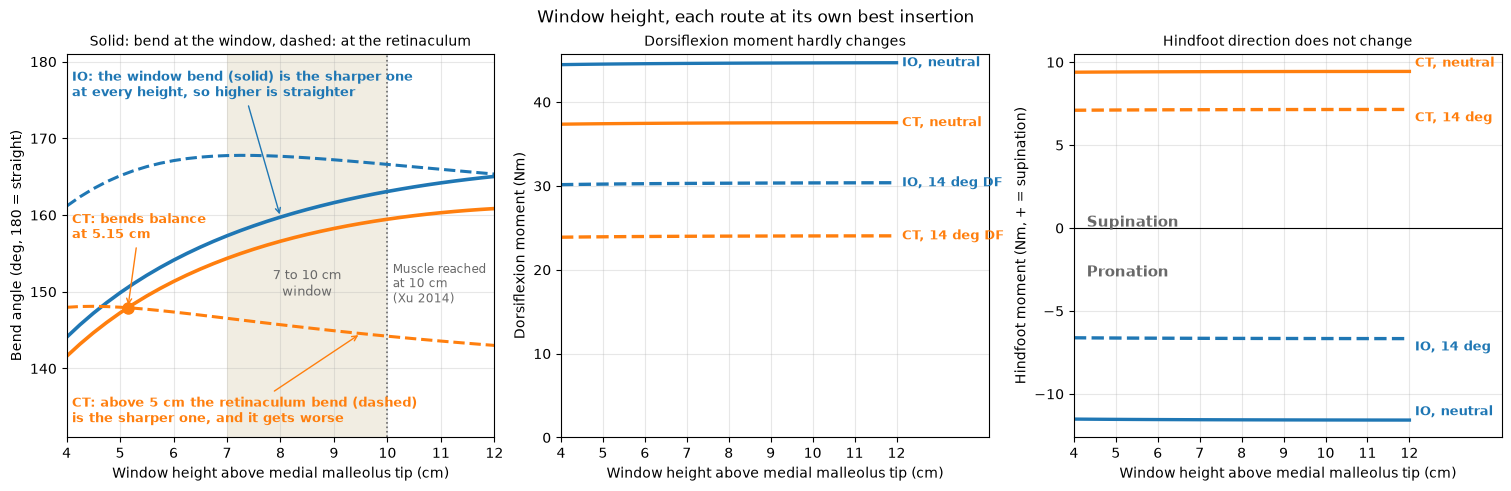

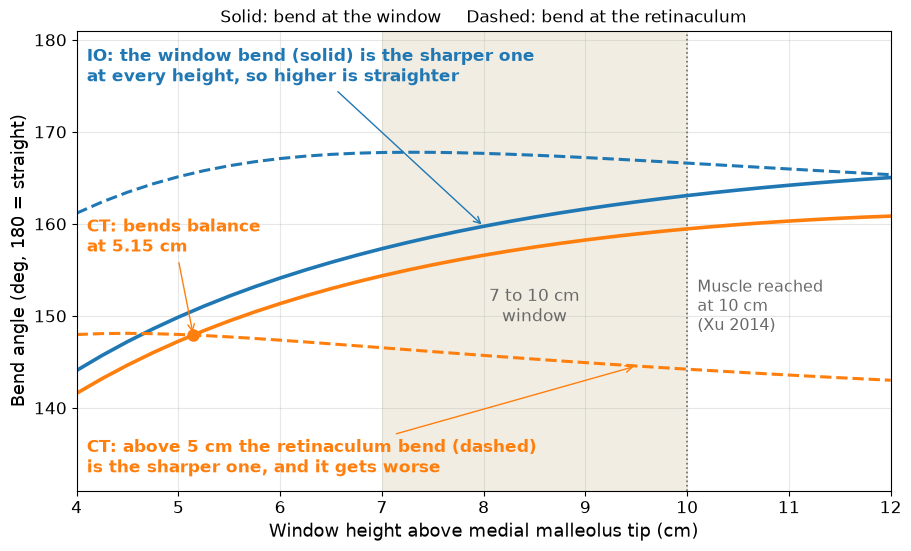

In [ ]:
def label_end(axis, x, y, text, colour, dy=0):
    """線的右端寫字，不用圖例。"""
    axis.annotate(text, (x, y), xytext=(4, dy), textcoords='offset points', va='center',
                  fontsize=9, color=colour, fontweight='bold')


def curve(route, field):
    """某條路徑某個欄位對高度的曲線。"""
    return [row['height_cm'] for row in table[route]], [row[field] for row in table[route]]


def draw_bends(axis, fontsize=10):
    """左圖：兩個轉折對高度。文字都放在線沒有經過的地方。"""
    axis.axvspan(7, 10, color='#e8e1cf', alpha=0.6, lw=0)
    axis.axvline(10, color='dimgrey', linestyle=':', linewidth=1.2)
    axis.text(8.5, 151, '7 to 10 cm\nwindow', ha='center', va='center', fontsize=fontsize - 1, color='dimgrey')
    axis.text(10.1, 151, 'Muscle reached\nat 10 cm\n(Xu 2014)', va='center', fontsize=fontsize - 1.5,
              color='dimgrey')
    for route in ROUTES:
        heights, window = curve(route, 'bend_window_deg')
        _, retinaculum = curve(route, 'bend_retinaculum_deg')
        axis.plot(heights, window, '-', color=COLOUR[route], linewidth=2.6)
        axis.plot(heights, retinaculum, '--', color=COLOUR[route], linewidth=2.2)
        at = BALANCE[route]
        if np.isfinite(at):  # 有交點才畫平衡點
            y = np.interp(at, heights, window)
            axis.plot(at, y, 'o', color=COLOUR[route], markersize=8, zorder=5)
            axis.annotate(f'{route}: bends balance\nat {at:.2f} cm', (at, y), xytext=(4.1, 157),
                          fontsize=fontsize - 1, color=COLOUR[route], fontweight='bold',
                          arrowprops={'arrowstyle': '->', 'color': COLOUR[route]})
    heights, window = curve('IO', 'bend_window_deg')
    axis.annotate('IO: the window bend (solid) is the sharper one\nat every height, so higher is straighter',
                  (8.0, np.interp(8.0, heights, window)), xytext=(4.1, 175.5), fontsize=fontsize - 1,
                  color=COLOUR['IO'], fontweight='bold', arrowprops={'arrowstyle': '->', 'color': COLOUR['IO']})
    heights, retinaculum = curve('CT', 'bend_retinaculum_deg')
    axis.annotate('CT: above 5 cm the retinaculum bend (dashed)\nis the sharper one, and it gets worse',
                  (9.5, np.interp(9.5, heights, retinaculum)), xytext=(4.1, 133), fontsize=fontsize - 1,
                  color=COLOUR['CT'], fontweight='bold', arrowprops={'arrowstyle': '->', 'color': COLOUR['CT']})
    axis.set_xlabel('Window height above medial malleolus tip (cm)', fontsize=fontsize)
    axis.set_ylabel('Bend angle (deg, 180 = straight)', fontsize=fontsize)
    axis.set_xlim(4, 12)
    axis.set_ylim(131, 181)  # 上下留空間給說明文字
    axis.grid(alpha=0.3)


figure, axes = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True)
draw_bends(axes[0])
axes[0].set_title('Solid: bend at the window, dashed: at the retinaculum', fontsize=10)
for route in ROUTES:
    heights = [row['height_cm'] for row in table[route]]
    for angle, style in ((0, '-'), (14, '--')):
        dorsi = [row[f'dorsi_moment_{angle}deg_Nm'] for row in table[route]]
        axes[1].plot(heights, dorsi, style, color=COLOUR[route], linewidth=2.4)
        label_end(axes[1], heights[-1], dorsi[-1], f'{route}, {"neutral" if angle == 0 else "14 deg DF"}',
                  COLOUR[route])
        side = [row[f'supination_moment_{angle}deg_Nm'] for row in table[route]]
        axes[2].plot(heights, side, style, color=COLOUR[route], linewidth=2.4)
        label_end(axes[2], heights[-1], side[-1], f'{route}, {"neutral" if angle == 0 else "14 deg"}',
                  COLOUR[route], dy=6 if angle == 0 else -6)
axes[1].set_ylim(bottom=0)
axes[1].set_ylabel('Dorsiflexion moment (Nm)')
axes[1].set_title('Dorsiflexion moment hardly changes', fontsize=10)
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].text(0.03, 0.55, 'Supination', transform=axes[2].transAxes, fontsize=11, fontweight='bold',
             color='dimgrey')  # 零線以上是旋後
axes[2].text(0.03, 0.42, 'Pronation', transform=axes[2].transAxes, fontsize=11, fontweight='bold',
             color='dimgrey')  # 零線以下是旋前
axes[2].set_ylabel('Hindfoot moment (Nm, + = supination)')
axes[2].set_title('Hindfoot direction does not change', fontsize=10)
for axis in axes[1:]:
    axis.set_xlabel('Window height above medial malleolus tip (cm)')
    axis.set_xlim(4, 14.2)  # 右邊留空間給線旁的字，字不能跑出框
    axis.set_xticks(range(4, 13))
    axis.grid(alpha=0.3)
figure.suptitle('Window height, each route at its own best insertion', fontsize=12)
plt.savefig(os.path.join(FIGURES, 'v2-p3-height-at-best.png'), dpi=200, bbox_inches='tight')
plt.show()

figure, axis = plt.subplots(figsize=(9, 5.4), constrained_layout=True)  # 投影片版，只有左圖
draw_bends(axis, fontsize=13)
axis.set_title('Solid: bend at the window     Dashed: bend at the retinaculum', fontsize=12)
axis.tick_params(labelsize=12)
plt.savefig(os.path.join(FIGURES, 'v2-p3-bends-slide.png'), dpi=200, bbox_inches='tight')
plt.show()

### 👀 4.1. 怎麼看這三張圖

1. **左圖**　藍色實線（IO 窗口那一彎）一路往上，藍色虛線一直在它上面，所以 IO 越高越直 / 橘色兩條在 5.15 cm 交叉，之後橘色虛線往下，CT 被支持帶那一彎拖住
2. **中圖**　背屈力矩四條都是水平線
3. **右圖**　零線以上是 CT 旋後、以下是 IO 旋前，也都是水平線，高度不改變方向
4. 投影片版 `v2-p3-bends-slide.png` 只有左圖，字比較大

### 📖 4.2. 投影片用的簡化版，一條路徑只畫一條線

1. 2026-09-19 她說 4.1 的線太多，要像一張示意圖那樣簡單
2. 每個高度只取**兩個彎裡比較彎的那一個**，這就是整條肌腱最卡的地方
3. 淺色底是臨床上開窗的 7 到 10 cm，點線是 10 cm，大體實驗在這裡已經撕到肌肉（Xu 2014）
4. 線旁邊直接寫結論，不用圖例
5. ✏️ 2026-09-19 下面加一條解剖條，和 MRI 對齊，全部從內踝尖量 / 8 cm 以下只有肌腱，8 cm 起少量肌肉、好剝（MRI），10 cm 以上硬剝會撕裂（Xu 2014）
   - ⚠️ MRI 上那條線是兩段接起來的，下段 81 mm 是內踝尖到肌肉開始，上段 65 mm 是再往上那一段，不是離內踝尖 6.5 cm

IO sharpest bend at 4, 7, 7.5, 10, 12 cm: [144.1, 157.3, 158.6, 163.1, 165.0]
CT sharpest bend at 4, 7, 7.5, 10, 12 cm: [141.6, 146.5, 146.1, 144.2, 143.0]


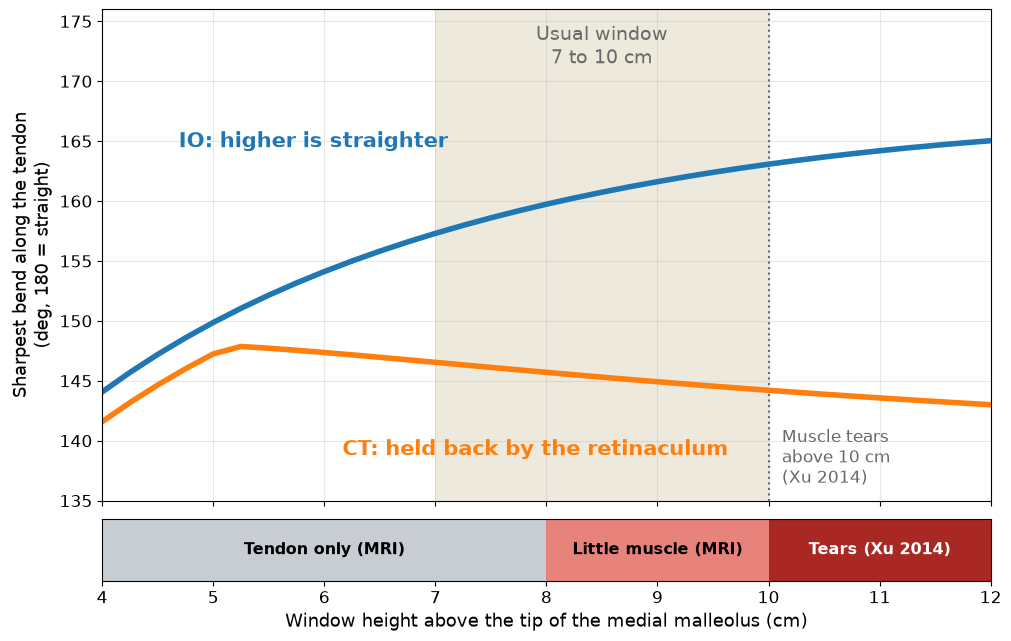

In [ ]:
figure, (axis, strip) = plt.subplots(
    2, 1,
    figsize=(10, 6.3),
    sharex=True,
    gridspec_kw={'height_ratios': [6, 0.75]},
    constrained_layout=True,
)
# 解剖條：肌肉的位置不是模型算的，是 MRI 和大體研究的數字
ZONES = [
    (4, 8, '#c8cdd4', 'Tendon only (MRI)', 'black'),
    (8, 10, '#e8837c', 'Little muscle (MRI)', 'black'),
    (10, 12, '#aa2823', 'Tears (Xu 2014)', 'white'),
]
for start, end, colour, words, ink in ZONES:
    strip.axvspan(start, end, color=colour, lw=0)
    strip.text((start + end) / 2, 0.5, words, ha='center', va='center', fontsize=11.5, color=ink,
               fontweight='bold')
strip.set_yticks([])
strip.set_ylim(0, 1)
axis.axvspan(7, 10, color='#e8e1cf', alpha=0.7, lw=0)  # 臨床開窗範圍
axis.axvline(10, color='dimgrey', linestyle=':', linewidth=1.5)
axis.text(8.5, 171.5, 'Usual window\n7 to 10 cm', ha='center', fontsize=14, color='dimgrey')
axis.text(10.12, 136.5, 'Muscle tears\nabove 10 cm\n(Xu 2014)', fontsize=12, color='dimgrey')
for route in ROUTES:
    heights = [row['height_cm'] for row in table[route]]
    axis.plot(heights, LIMITING[route], '-', color=COLOUR[route], linewidth=4)  # 比較彎的那一個
WORDS = {'IO': ('IO: higher is straighter', 5.9, 164.5), 'CT': ('CT: held back by the retinaculum', 7.9, 138.8)}
for route, (words, x, y) in WORDS.items():  # 字放在線旁邊的空白處，不壓線
    axis.text(x, y, words, ha='center', fontsize=15, fontweight='bold', color=COLOUR[route])
axis.set_xlim(4, 12)
axis.set_ylim(135, 176)
strip.set_xlabel('Window height above the tip of the medial malleolus (cm)', fontsize=13)
axis.set_ylabel('Sharpest bend along the tendon\n(deg, 180 = straight)', fontsize=13)
axis.tick_params(labelsize=12)
strip.tick_params(labelsize=12)
axis.grid(alpha=0.3)
plt.savefig(os.path.join(FIGURES, 'v2-p3-straightness-slide.png'), dpi=200, bbox_inches='tight')
plt.show()
for route in ROUTES:
    heights = [row['height_cm'] for row in table[route]]
    print(route, 'sharpest bend at 4, 7, 7.5, 10, 12 cm:',
          [round(float(np.interp(h, heights, LIMITING[route])), 1) for h in (4, 7, 7.5, 10, 12)])

### 👀 4.2. 簡化版怎麼看

1. **藍線一路往上**　IO 越高越直，在 7 到 10 cm 裡面，10 cm 最直
2. **橘線 5 cm 以後往下**　CT 被支持帶那一彎拖住，開高一點沒有幫助
3. 兩條線都在淺色底裡，但只有 IO 能靠開高一點變直
4. **下面那條解剖條**　8 cm 以下只有肌腱，窗口的上半段（8 到 10 cm）有少量肌肉，好剝，10 cm 以上剝了會撕裂 / 所以 IO 的「越高越直」停在 10 cm

## 5. OpenSim 模型

### 📖 5.1. 每條路徑存四個高度，存完重新讀回來對帳

1. 高度 4、7.5、10、12 cm，有平衡高度的路徑再加一個，取到 0.05 cm
2. 7.5 cm 就是第二部分用的高度
3. 重新讀回來，中立位和 14° 的兩個力臂要和存檔前一樣
4. IO 藍、CT 橘

In [ ]:
os.makedirs(MODELS_DIR, exist_ok=True)


def rgb(colour):
    colour = colour.lstrip('#')
    return osim.Vec3(*(int(colour[i:i + 2], 16) / 255 for i in (0, 2, 4)))


SAVE_HEIGHTS = {}  # 4、7.5、10、12 cm，有平衡高度就再加一個
for route in ROUTES:
    heights = {4.0, 7.5, 10.0, 12.0}
    if np.isfinite(BALANCE[route]):
        heights.add(round(BALANCE[route] * 20) / 20)
    SAVE_HEIGHTS[route] = sorted(heights)
index_rows, worst = [], 0.0
for route, z in ROUTES.items():
    position, xyz, label = BEST[route]
    for height in tqdm(SAVE_HEIGHTS[route], desc=f'{route} models'):
        engine.set_route(z, via_y_from_height(height), insertion=xyz)
        engine._pose(0.0, 0.0)  # 存檔前擺回中立位
        expected = engine.sweep_ankle(REPORT)
        bends = engine.bend_angles()
        engine.donor.getGeometryPath().upd_Appearance().set_color(rgb(COLOUR[route]))
        stem = f'V2_P3_{route}_pos{position:.2f}_h{height:05.2f}cm'
        engine.model.setName(stem)
        path = os.path.join(MODELS_DIR, stem + '.osim')
        engine.model.printToXML(path)
        again = TransferEngine(path).sweep_ankle(REPORT)
        gap = max(max(abs(again[i]['arm_ankle_mm'] - expected[i]['arm_ankle_mm']),
                      abs(again[i]['arm_subtalar_mm'] - expected[i]['arm_subtalar_mm'])) for i in range(2))
        worst = max(worst, gap)
        index_rows.append({'file': stem + '.osim', 'route': route, 'position': position, 'insertion': label,
                           'height_cm': height, 'bend_window_deg': round(bends['window_deg'], 2),
                           'bend_retinaculum_deg': round(bends['retinaculum_deg'], 2),
                           'dorsi_arm_14deg_mm': round(expected[1]['arm_ankle_mm'], 4),
                           'supination_arm_14deg_mm': round(expected[1]['arm_subtalar_mm'], 4),
                           'reload_difference_mm': gap})
print(f'{len(index_rows)} models saved, largest reload difference {worst:.2e} mm')
for row in index_rows:
    print(f"  {row['file']:36s} window {row['bend_window_deg']:6.1f}  retinaculum {row['bend_retinaculum_deg']:6.1f} deg")

9 models saved, largest reload difference 0.00e+00 mm
  V2_P3_IO_pos2.75_h04.00cm.osim       window  144.1  retinaculum  161.2 deg
  V2_P3_IO_pos2.75_h07.50cm.osim       window  158.6  retinaculum  167.8 deg
  V2_P3_IO_pos2.75_h10.00cm.osim       window  163.1  retinaculum  166.6 deg
  V2_P3_IO_pos2.75_h12.00cm.osim       window  165.0  retinaculum  165.3 deg
  V2_P3_CT_pos1.00_h04.00cm.osim       window  141.6  retinaculum  148.0 deg
  V2_P3_CT_pos1.00_h05.15cm.osim       window  147.9  retinaculum  147.9 deg
  V2_P3_CT_pos1.00_h07.50cm.osim       window  155.6  retinaculum  146.1 deg
  V2_P3_CT_pos1.00_h10.00cm.osim       window  159.5  retinaculum  144.2 deg
  V2_P3_CT_pos1.00_h12.00cm.osim       window  160.8  retinaculum  143.0 deg


### 👀 5.1. 模型

1. ✅ IO 四個、CT 五個（多一個 5.15 cm 平衡高度），共 9 個
2. ✅ 重新讀回來，力臂差 0 mm
3. 檔名裡有路徑、止點位置和高度，例如 `V2_P3_IO_pos2.75_h10.00cm.osim`

### 📖 5.2. 總覽模型，高度由淺到深

1. 每條路徑的 4、7.5、12 cm 三條放進同一個模型，同一個顏色由淺到深
2. GUI 從正面看，就看得到開窗點往上移時兩個彎怎麼變
3. ⛔ 裡面有六條轉位肌，**只能看**，不能跑分析

In [ ]:
def muscle_block(path):
    """讀出一個 .osim 裡 tib_post_l 的整段 XML，和整份文字。"""
    text = open(path, encoding='utf-8').read()
    start = text.index('<Thelen2003Muscle name="tib_post_l">')
    end = text.index('</Thelen2003Muscle>', start) + len('</Thelen2003Muscle>')
    return text, text[start:end], start, end


def recolour(block, name, colour):
    """改肌肉和路徑點的名字，換顏色。"""
    block = block.replace('name="tib_post_l"', f'name="{name}"', 1)
    block = block.replace('name="tib_post_l-P', f'name="{name}-P')
    colour = colour.lstrip('#')
    red, green, blue = (int(colour[i:i + 2], 16) / 255 for i in (0, 2, 4))
    return re.sub(r'<color>[^<]*</color>', f'<color>{red:.4f} {green:.4f} {blue:.4f}</color>', block, count=1)


SHADES = {'IO': ['#9ecae1', '#4292c6', '#08306b'], 'CT': ['#fdd0a2', '#fd8d3c', '#a63603']}  # 低到高
members = []
for route in ROUTES:
    for height, shade in zip((4.0, 7.5, 12.0), SHADES[route]):
        file = next(r['file'] for r in index_rows if r['route'] == route and r['height_cm'] == height)
        members.append((os.path.join(MODELS_DIR, file), f'tib_post_l_{route}_h{height:05.2f}cm'.replace('.', 'p'), shade))
base_text, _, start, end = muscle_block(MODEL)
blocks = [recolour(muscle_block(path)[1], name, colour) for path, name, colour in members]
text = base_text[:start] + '\n\t\t\t\t'.join(blocks) + base_text[end:]
text = re.sub(r'<Model name="[^"]*">', '<Model name="V2_P3_height_overview_VIEW_ONLY">', text, count=1)
out = os.path.join(MODELS_DIR, 'V2_P3_height_overview_VIEW_ONLY.osim')
open(out, 'w', encoding='utf-8').write(text)
check = osim.Model(out)
check.initSystem()
names = [check.getMuscles().get(i).getName() for i in range(check.getMuscles().getSize())]
print('overview paths:', [n for _, n, _ in members if n in names])

with open(os.path.join(MODELS_DIR, 'models_index.csv'), 'w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(index_rows[0]))
    writer.writeheader()
    writer.writerows(index_rows)

overview paths: ['tib_post_l_IO_h04p00cm', 'tib_post_l_IO_h07p50cm', 'tib_post_l_IO_h12p00cm', 'tib_post_l_CT_h04p00cm', 'tib_post_l_CT_h07p50cm', 'tib_post_l_CT_h12p00cm']


### 👀 5.2. 總覽模型

1. ✅ 六條都在，IO 三條由淺藍到深藍是 4、7.5、12 cm，CT 由淺橘到深橘也一樣
2. GUI 從正面看，開窗點越高顏色越深
3. ⛔ 只能看，不能跑分析